In [3]:
%pip install -q "numpy>=1.23" "pandas>=1.5" "matplotlib>=3.6" "scikit-learn>=1.2" joblib psutil

Note: you may need to restart the kernel to use updated packages.


# Importing packages and configuring the experiment

In [4]:
import gc
import json
import math
import os
import re
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from packaging.version import Version
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_pinball_loss,
    mean_squared_error,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
MODEL_ID = 1
DATA_ROOT = Path(r"C:\Users\user\Desktop\Dataset IIV\Models")
MAX_SAMPLES_PER_EVENT = 6000
MAX_ITERATIONS = 120
MAX_LEAF_NODES = 15
MIN_SAMPLES_LEAF = 40
LEARNING_RATE = 0.06

# Forecast horizons are measured in simulation timesteps.
HORIZONS = [1, 3, 6]
QUANTILES = [0.10, 0.50, 0.90]
INTERVAL_ALPHA = 0.20

# Set True if the 2D water_level column is a water-surface elevation.
# In that case, flood depth is calculated as water_level minus centroid elevation.
# Set False if water_level is already a depth above the ground.
LEVEL_IS_ELEVATION = True

# These are analytical thresholds for sensitivity analysis.
DEPTH_THRESHOLDS_FT = [0.25, 0.50, 1.00]

OUTPUT_DIR = Path(f"urbanflood_results_model_{MODEL_ID}")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if Version(sklearn.__version__) < Version("1.2"):
    raise RuntimeError(
        f"scikit-learn {sklearn.__version__} is installed. Rerunning Cell 1 to restart the kernel, and run the notebook again."
    )

if (DATA_ROOT / "Model_1").exists():
    MODELS_DIR = DATA_ROOT
elif (DATA_ROOT / "Models").exists():
    MODELS_DIR = DATA_ROOT / "Models"
else:
    raise FileNotFoundError(
        
    )

MODEL_DIR = MODELS_DIR / f"Model_{MODEL_ID}"
TRAIN_DIR = MODEL_DIR / "train"
OFFICIAL_TEST_DIR = MODEL_DIR / "test"

if not TRAIN_DIR.exists():
    raise FileNotFoundError(f"Training folder not found: {TRAIN_DIR}")

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Selected model:", MODEL_ID)
print("Model directory:", MODEL_DIR)
print("Output directory:", OUTPUT_DIR.resolve())

Python version: 3.13.9
Pandas version: 2.3.3
Scikit-learn version: 1.6.1
Selected model: 1
Model directory: C:\Users\user\Desktop\Dataset IIV\Models\Model_1
Output directory: C:\Users\user\urbanflood_results_model_1


# Doing inventory analysis of the folders and inspecting the CSV files

In [5]:
def get_event_directories(folder):
    event_folders = [p for p in folder.iterdir() if p.is_dir() and re.fullmatch(r"event_\d+", p.name)]
    return sorted(event_folders, key=lambda p: int(p.name.split("_")[1]))

train_event_dirs = get_event_directories(TRAIN_DIR)
test_event_dirs = get_event_directories(OFFICIAL_TEST_DIR) if OFFICIAL_TEST_DIR.exists() else []

print("Training events:", len(train_event_dirs))
print("Official test events:", len(test_event_dirs))
print("First training events:", [p.name for p in train_event_dirs[:10]])
print("First official test events:", [p.name for p in test_event_dirs[:10]])

if not train_event_dirs:
    raise RuntimeError("No event folders were found in the selected training directory.")

sample_event_dir = train_event_dirs[0]
files_to_inspect = [
    TRAIN_DIR / "2d_nodes_static.csv",
    sample_event_dir / "2d_nodes_dynamic_all.csv",
    sample_event_dir / "timesteps.csv",
]

for file_path in files_to_inspect:
    print("\nFile:", file_path)
    if not file_path.exists():
        print("File not found. Check the directory and filename.")
        continue
    preview = pd.read_csv(file_path, nrows=5)
    print("Columns:", preview.columns.tolist())
    print(preview.head(3).to_string(index=False))

def infer_median_timestep_minutes(timesteps_file):
    if not timesteps_file.exists():
        return None
    metadata = pd.read_csv(timesteps_file)
    for column in metadata.columns:
        clean_name = re.sub(r"[^a-z0-9]+", "", str(column).lower())
        if not any(token in clean_name for token in ["timestamp", "datetime", "actualtime", "date"]):
            continue
        values = metadata[column].dropna()
        if len(values) < 2:
            continue
        if pd.to_numeric(values, errors="coerce").notna().mean() > 0.90:
            continue
        parsed = pd.to_datetime(values, errors="coerce", utc=True)
        if parsed.notna().sum() >= 2:
            differences = parsed.dropna().sort_values().diff().dt.total_seconds() / 60.0
            differences = differences[differences > 0]
            if len(differences):
                return float(differences.median())
        durations = pd.to_timedelta(values, errors="coerce")
        if durations.notna().sum() >= 2:
            differences = durations.dropna().sort_values().diff().dt.total_seconds() / 60.0
            differences = differences[differences > 0]
            if len(differences):
                return float(differences.median())
    return None


MEDIAN_TIMESTEP_MINUTES = infer_median_timestep_minutes(sample_event_dir / "timesteps.csv")
if MEDIAN_TIMESTEP_MINUTES is None:
    print("A time interval could not be read automatically. Forecast horizons will be reported in timesteps.")
else:
    print("Median simulation timestep interval (minutes):", MEDIAN_TIMESTEP_MINUTES)

Training events: 68
Official test events: 29
First training events: ['event_1', 'event_2', 'event_3', 'event_4', 'event_6', 'event_7', 'event_9', 'event_10', 'event_11', 'event_12']
First official test events: ['event_5', 'event_8', 'event_18', 'event_22', 'event_26', 'event_29', 'event_31', 'event_33', 'event_35', 'event_37']

File: C:\Users\user\Desktop\Dataset IIV\Models\Model_1\train\2d_nodes_static.csv
Columns: ['node_idx', 'position_x', 'position_y', 'area', 'roughness', 'min_elevation', 'elevation', 'aspect', 'curvature', 'flow_accumulation']
 node_idx  position_x  position_y      area  roughness  min_elevation  elevation    aspect  curvature  flow_accumulation
        0   803051.56   350382.44 825.63544       0.06      329.75012  331.09375 185.94380   0.000082                8.0
        1   803076.56   350382.44 616.87900       0.06      329.84910  330.90625 182.54686   0.000036                1.0
        2   803101.56   350382.44 611.14510       0.06      329.69390  330.56250 

# Identify the node, timestep, water-level, rainfall, and volume columns

In [6]:
def normalize_column_name(name):
    return re.sub(r"[^a-z0-9]+", "", str(name).lower())

def find_column(columns, aliases, required=True):
    normalized = {normalize_column_name(c): c for c in columns}
    for alias in aliases:
        key = normalize_column_name(alias)
        if key in normalized:
            return normalized[key]
    for alias in aliases:
        key = normalize_column_name(alias)
        if len(key) < 4:
            continue
        for norm_name, original_name in normalized.items():
            if key and key in norm_name:
                return original_name
    if required:
        raise KeyError(
            f"Could not identify a column from these aliases: {aliases}. Available columns: {list(columns)}"
        )
    return None


COLUMN_OVERRIDES = {
    "dynamic_node": None,
    "timestep": None,
    "water_level": None,
    "rainfall": None,
    "water_volume": None,
    "static_node": None,
}

sample_dynamic_path = sample_event_dir / "2d_nodes_dynamic_all.csv"
static_path = TRAIN_DIR / "2d_nodes_static.csv"

dynamic_header = pd.read_csv(sample_dynamic_path, nrows=0).columns.tolist()
static_header = pd.read_csv(static_path, nrows=0).columns.tolist()

DYNAMIC_NODE_COL = COLUMN_OVERRIDES["dynamic_node"] or find_column(
    dynamic_header, ["node_id", "node_index", "node_idx", "cell_id", "node", "id"]
)
TIMESTEP_COL = COLUMN_OVERRIDES["timestep"] or find_column(
    dynamic_header, ["timestep", "time_step", "timestep_index", "time_index", "step", "time_idx"]
)
WATER_LEVEL_COL = COLUMN_OVERRIDES["water_level"] or find_column(
    dynamic_header, ["water_level", "2d_water_level", "waterlevel", "level"]
)
RAINFALL_COL = COLUMN_OVERRIDES["rainfall"] or find_column(
    dynamic_header, ["rainfall_depth", "rainfall", "rain_depth", "rain"]
)
WATER_VOLUME_COL = COLUMN_OVERRIDES["water_volume"] or find_column(
    dynamic_header, ["water_volume", "volume"], required=False
)
STATIC_NODE_COL = COLUMN_OVERRIDES["static_node"] or find_column(
    static_header, ["node_id", "node_index", "node_idx", "cell_id", "node", "id"]
)

print("Dynamic node column:", DYNAMIC_NODE_COL)
print("Timestep column:", TIMESTEP_COL)
print("Water-level column:", WATER_LEVEL_COL)
print("Rainfall column:", RAINFALL_COL)
print("Water-volume column:", WATER_VOLUME_COL)
print("Static node column:", STATIC_NODE_COL)

Dynamic node column: node_idx
Timestep column: timestep
Water-level column: water_level
Rainfall column: rainfall
Water-volume column: water_volume
Static node column: node_idx


# Load the small static surface-node table

In [7]:
static_raw = pd.read_csv(static_path)
static_raw["_node_key"] = static_raw[STATIC_NODE_COL].astype(str)

static_features = static_raw[["_node_key"]].copy()
static_feature_columns = []
static_column_lookup = {}

for column in static_raw.columns:
    if column in [STATIC_NODE_COL, "_node_key"]:
        continue
    numeric_values = pd.to_numeric(static_raw[column], errors="coerce")
    if numeric_values.notna().mean() >= 0.80:
        new_name = "static_" + normalize_column_name(column)
        static_features[new_name] = numeric_values.astype("float32")
        static_feature_columns.append(new_name)
        static_column_lookup[normalize_column_name(column)] = new_name

if static_features["_node_key"].duplicated().any():
    raise ValueError("The static 2D node table contains duplicate node identifiers.")

ELEVATION_FEATURE = None
for candidate in ["centroid_elevation", "2d_centroid_elevation", "elevation", "minimum_elevation", "min_elevation"]:
    key = normalize_column_name(candidate)
    if key in static_column_lookup:
        ELEVATION_FEATURE = static_column_lookup[key]
        break

if LEVEL_IS_ELEVATION and ELEVATION_FEATURE is None:
    raise KeyError(
        "LEVEL_IS_ELEVATION is True, but no centroid or terrain elevation column was found. "
        "Inspect the static columns and set the correct elevation feature manually."
    )

print("Number of static 2D nodes:", len(static_features))
print("Static numeric features:", static_feature_columns)
print("Elevation feature used for depth calculation:", ELEVATION_FEATURE)
print(static_features.head())

Number of static 2D nodes: 3716
Static numeric features: ['static_positionx', 'static_positiony', 'static_area', 'static_roughness', 'static_minelevation', 'static_elevation', 'static_aspect', 'static_curvature', 'static_flowaccumulation']
Elevation feature used for depth calculation: static_elevation
  _node_key  static_positionx  static_positiony  static_area  static_roughness  static_minelevation  static_elevation  static_aspect  static_curvature  \
0         0       803051.5625       350382.4375   825.635437              0.06           329.750122         331.09375     185.943802          0.000082   
1         1       803076.5625       350382.4375   616.879028              0.06           329.849091         330.90625     182.546860          0.000036   
2         2       803101.5625       350382.4375   611.145081              0.06           329.693909         330.56250     140.860703          0.000004   
3         3       803126.5625       350382.4375   605.411133              0.06   

# Building memory-conscious samples from one event
## Only the 2D node dynamic file is read. Each event is processed separately. The target is the future water level at the same surface node after 1, 3, or 6 timesteps.

In [8]:
def convert_timestep_to_number(values):
    numeric = pd.to_numeric(values, errors="coerce")
    if numeric.notna().all():
        return numeric.astype("float64")

    parsed_datetime = pd.to_datetime(values, errors="coerce")
    if parsed_datetime.notna().all():
        return (parsed_datetime.astype("int64") / 1e9).astype("float64")

    codes, _ = pd.factorize(values.astype(str), sort=True)
    return pd.Series(codes, index=values.index, dtype="float64")


def sample_rows_by_node(frame, max_rows, seed):
    if len(frame) <= max_rows:
        return frame.copy()

    one_per_node = frame.groupby("_node_key", group_keys=False).sample(
        n=1, random_state=seed
    )

    if len(one_per_node) >= max_rows:
        return one_per_node.sample(n=max_rows, random_state=seed).copy()

    remaining = frame.drop(index=one_per_node.index)
    number_to_add = min(max_rows - len(one_per_node), len(remaining))
    extra = remaining.sample(n=number_to_add, random_state=seed)
    sampled = pd.concat([one_per_node, extra], axis=0)
    return sampled.sample(frac=1, random_state=seed).reset_index(drop=True)

DYNAMIC_FEATURE_COLUMNS = [
    "wl_lag_0", "wl_lag_1", "wl_lag_2",
    "rain_lag_0", "rain_lag_1", "rain_lag_2",
    "rain_sum_3", "rain_sum_6", "time_fraction",
]

if WATER_VOLUME_COL is not None:
    DYNAMIC_FEATURE_COLUMNS += ["volume_lag_0", "volume_lag_1"]

FEATURE_COLUMNS = DYNAMIC_FEATURE_COLUMNS + static_feature_columns
TARGET_COLUMNS = [f"target_h{h}" for h in HORIZONS]


def build_event_samples(event_dir, max_rows=MAX_SAMPLES_PER_EVENT, seed=RANDOM_STATE):
    dynamic_path = event_dir / "2d_nodes_dynamic_all.csv"
    if not dynamic_path.exists():
        raise FileNotFoundError(f"Missing dynamic file: {dynamic_path}")

    columns_to_read = [DYNAMIC_NODE_COL, TIMESTEP_COL, WATER_LEVEL_COL, RAINFALL_COL]
    if WATER_VOLUME_COL is not None:
        columns_to_read.append(WATER_VOLUME_COL)
    columns_to_read = list(dict.fromkeys(columns_to_read))

    dynamic = pd.read_csv(dynamic_path, usecols=columns_to_read, low_memory=False)
    dynamic["node_id"] = dynamic[DYNAMIC_NODE_COL].astype(str)
    dynamic["_node_key"] = dynamic["node_id"]
    dynamic["step"] = convert_timestep_to_number(dynamic[TIMESTEP_COL])
    dynamic["water_level"] = pd.to_numeric(dynamic[WATER_LEVEL_COL], errors="coerce")
    dynamic["rainfall"] = pd.to_numeric(dynamic[RAINFALL_COL], errors="coerce").fillna(0.0)

    if WATER_VOLUME_COL is not None:
        dynamic["water_volume"] = pd.to_numeric(dynamic[WATER_VOLUME_COL], errors="coerce")

    dynamic = dynamic.dropna(subset=["node_id", "step", "water_level"])
    dynamic = dynamic.sort_values(["_node_key", "step"]).reset_index(drop=True)

    if dynamic.duplicated(subset=["_node_key", "step"]).any():
        raise ValueError(
            f"Duplicate node and timestep rows were found in {dynamic_path}. "
            "Check the dynamic CSV before continuing."
        )

    grouped = dynamic.groupby("_node_key", sort=False)
    dynamic["wl_lag_0"] = dynamic["water_level"]
    dynamic["wl_lag_1"] = grouped["water_level"].shift(1)
    dynamic["wl_lag_2"] = grouped["water_level"].shift(2)

    dynamic["rain_lag_0"] = dynamic["rainfall"]
    dynamic["rain_lag_1"] = grouped["rainfall"].shift(1)
    dynamic["rain_lag_2"] = grouped["rainfall"].shift(2)
    dynamic["rain_sum_3"] = dynamic.groupby("_node_key")["rainfall"].transform(
        lambda series: series.rolling(3, min_periods=1).sum()
    )
    dynamic["rain_sum_6"] = dynamic.groupby("_node_key")["rainfall"].transform(
        lambda series: series.rolling(6, min_periods=1).sum()
    )

    if WATER_VOLUME_COL is not None:
        dynamic["volume_lag_0"] = dynamic["water_volume"]
        dynamic["volume_lag_1"] = dynamic.groupby("_node_key")["water_volume"].shift(1)

    step_min = dynamic["step"].min()
    step_max = dynamic["step"].max()
    if step_max > step_min:
        dynamic["time_fraction"] = (dynamic["step"] - step_min) / (step_max - step_min)
    else:
        dynamic["time_fraction"] = 0.0

    for horizon in HORIZONS:
        dynamic[f"target_h{horizon}"] = dynamic.groupby("_node_key")["water_level"].shift(-horizon)

    dynamic = dynamic.merge(static_features, on="_node_key", how="left", validate="many_to_one")
    dynamic = dynamic.dropna(subset=TARGET_COLUMNS + ["wl_lag_1", "wl_lag_2", "rain_lag_1", "rain_lag_2"])

    for column in FEATURE_COLUMNS:
        dynamic[column] = pd.to_numeric(dynamic[column], errors="coerce").astype("float32")

    keep_columns = ["event_id", "node_id", "_node_key", "step", "water_level"]
    keep_columns += FEATURE_COLUMNS + TARGET_COLUMNS
    dynamic["event_id"] = event_dir.name
    result = dynamic[keep_columns].copy()

    result = sample_rows_by_node(result, max_rows=max_rows, seed=seed)
    del dynamic
    gc.collect()
    return result

print("Number of model features:", len(FEATURE_COLUMNS))
print("Feature columns:", FEATURE_COLUMNS)
print("Target columns:", TARGET_COLUMNS)

Number of model features: 20
Feature columns: ['wl_lag_0', 'wl_lag_1', 'wl_lag_2', 'rain_lag_0', 'rain_lag_1', 'rain_lag_2', 'rain_sum_3', 'rain_sum_6', 'time_fraction', 'volume_lag_0', 'volume_lag_1', 'static_positionx', 'static_positiony', 'static_area', 'static_roughness', 'static_minelevation', 'static_elevation', 'static_aspect', 'static_curvature', 'static_flowaccumulation']
Target columns: ['target_h1', 'target_h3', 'target_h6']


# Split complete rainfall events into training, validation, and final evaluation groups

In [9]:
event_names = [p.name for p in train_event_dirs]
rng = np.random.default_rng(RANDOM_STATE)
shuffled_events = np.array(event_names, dtype=object)
rng.shuffle(shuffled_events)

number_of_events = len(shuffled_events)
number_test_events = max(1, int(round(number_of_events * 0.15)))
number_validation_events = max(1, int(round(number_of_events * 0.15)))

if number_test_events + number_validation_events >= number_of_events:
    raise ValueError("There are too few training events for the requested event-level split.")

EVALUATION_EVENTS = sorted(shuffled_events[:number_test_events].tolist())
VALIDATION_EVENTS = sorted(
    shuffled_events[number_test_events:number_test_events + number_validation_events].tolist()
)
TRAIN_EVENTS = sorted(
    shuffled_events[number_test_events + number_validation_events:].tolist()
)

print("Training events:", len(TRAIN_EVENTS))
print("Validation events:", len(VALIDATION_EVENTS))
print("Final evaluation events:", len(EVALUATION_EVENTS))
print("Training event names:", TRAIN_EVENTS)
print("Validation event names:", VALIDATION_EVENTS)
print("Evaluation event names:", EVALUATION_EVENTS)

Training events: 48
Validation events: 10
Final evaluation events: 10
Training event names: ['event_1', 'event_11', 'event_12', 'event_13', 'event_14', 'event_15', 'event_16', 'event_17', 'event_19', 'event_20', 'event_24', 'event_25', 'event_28', 'event_3', 'event_30', 'event_34', 'event_36', 'event_38', 'event_4', 'event_40', 'event_41', 'event_43', 'event_45', 'event_47', 'event_49', 'event_50', 'event_54', 'event_55', 'event_57', 'event_58', 'event_61', 'event_63', 'event_64', 'event_68', 'event_70', 'event_71', 'event_72', 'event_76', 'event_78', 'event_79', 'event_82', 'event_84', 'event_85', 'event_86', 'event_9', 'event_92', 'event_93', 'event_94']
Validation event names: ['event_2', 'event_32', 'event_39', 'event_46', 'event_56', 'event_60', 'event_7', 'event_77', 'event_91', 'event_96']
Evaluation event names: ['event_10', 'event_21', 'event_23', 'event_27', 'event_6', 'event_74', 'event_87', 'event_89', 'event_90', 'event_95']


# Processing the events one at a time

In [10]:
event_path_lookup = {p.name: p for p in train_event_dirs}
def collect_split_samples(event_list, split_name):
    collected = []
    for position, event_name in enumerate(event_list, start=1):
        event_frame = build_event_samples(
            event_path_lookup[event_name],
            max_rows=MAX_SAMPLES_PER_EVENT,
            seed=RANDOM_STATE + position,
        )
        collected.append(event_frame)
        print(
            f"{split_name}: {position}/{len(event_list)} | {event_name} | "
            f"sample rows: {len(event_frame):,}"
        )
        del event_frame
        gc.collect()

    if not collected:
        raise RuntimeError(f"No samples were created for {split_name}.")

    combined = pd.concat(collected, ignore_index=True)
    del collected
    gc.collect()
    return combined

train_samples = collect_split_samples(TRAIN_EVENTS, "Training")
validation_samples = collect_split_samples(VALIDATION_EVENTS, "Validation")
evaluation_samples = collect_split_samples(EVALUATION_EVENTS, "Evaluation")

print("\nTraining sample shape:", train_samples.shape)
print("Validation sample shape:", validation_samples.shape)
print("Evaluation sample shape:", evaluation_samples.shape)
print("Training sample memory in MB:", round(train_samples.memory_usage(deep=True).sum() / 1024**2, 2))

Training: 1/48 | event_1 | sample rows: 6,000
Training: 2/48 | event_11 | sample rows: 6,000
Training: 3/48 | event_12 | sample rows: 6,000
Training: 4/48 | event_13 | sample rows: 6,000
Training: 5/48 | event_14 | sample rows: 6,000
Training: 6/48 | event_15 | sample rows: 6,000
Training: 7/48 | event_16 | sample rows: 6,000
Training: 8/48 | event_17 | sample rows: 6,000
Training: 9/48 | event_19 | sample rows: 6,000
Training: 10/48 | event_20 | sample rows: 6,000
Training: 11/48 | event_24 | sample rows: 6,000
Training: 12/48 | event_25 | sample rows: 6,000
Training: 13/48 | event_28 | sample rows: 6,000
Training: 14/48 | event_3 | sample rows: 6,000
Training: 15/48 | event_30 | sample rows: 6,000
Training: 16/48 | event_34 | sample rows: 6,000
Training: 17/48 | event_36 | sample rows: 6,000
Training: 18/48 | event_38 | sample rows: 6,000
Training: 19/48 | event_4 | sample rows: 6,000
Training: 20/48 | event_40 | sample rows: 6,000
Training: 21/48 | event_41 | sample rows: 6,000
Trai

# Exploratory checks and the water-level interpretation

Current water-level distribution:
count    288000.000000
mean        322.114227
std          14.376454
min         293.149200
1%          297.899373
10%         302.870471
50%         321.794113
90%         344.352121
99%         357.642824
max         360.036804
Name: wl_lag_0, dtype: float64

Static terrain elevation distribution:
count    288000.000000
mean        323.165161
std          14.489771
min         293.812500
1%          298.281250
10%         303.125000
50%         322.812500
90%         345.250000
99%         358.406250
max         360.218750
Name: static_elevation, dtype: float64


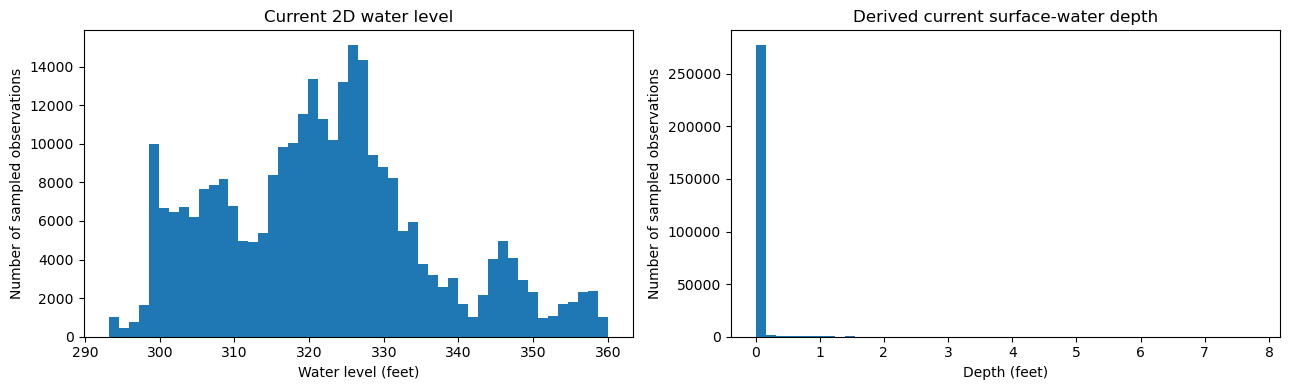

Median current surface-water depth (feet): 0.0
Configured level interpretation: surface elevation


In [11]:
print("Current water-level distribution:")
print(train_samples["wl_lag_0"].describe(percentiles=[0.01, 0.10, 0.50, 0.90, 0.99]))

if ELEVATION_FEATURE is not None:
    print("\nStatic terrain elevation distribution:")
    print(train_samples[ELEVATION_FEATURE].describe(percentiles=[0.01, 0.10, 0.50, 0.90, 0.99]))

if LEVEL_IS_ELEVATION:
    current_depth = np.maximum(
        train_samples["wl_lag_0"].to_numpy() - train_samples[ELEVATION_FEATURE].to_numpy(),
        0.0,
    )
else:
    current_depth = np.maximum(train_samples["wl_lag_0"].to_numpy(), 0.0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(train_samples["wl_lag_0"].dropna(), bins=50)
axes[0].set_title("Current 2D water level")
axes[0].set_xlabel("Water level (feet)")
axes[0].set_ylabel("Number of sampled observations")

axes[1].hist(current_depth, bins=50)
axes[1].set_title("Derived current surface-water depth")
axes[1].set_xlabel("Depth (feet)")
axes[1].set_ylabel("Number of sampled observations")
plt.tight_layout()
plt.show()
print("Median current surface-water depth (feet):", round(float(np.nanmedian(current_depth)), 4))
print("Configured level interpretation:", "surface elevation" if LEVEL_IS_ELEVATION else "depth above ground")

if LEVEL_IS_ELEVATION and ELEVATION_FEATURE is None:
    raise RuntimeError("Terrain elevation is required to calculate surface-water depth.")

# Define the quantile models and evaluation functions
## Three models are fitted for each forecast horizon. They estimate the 10th, 50th, and 90th percentiles of the future water level. The 10th to 90th percentile range is an 80% nominal prediction interval before calibration. This is a tree-ensemble machine-learning model, not a deep neural network. It is intended as a strong, resource-conscious baseline; a later paper extension can compare it with a small temporal neural network or a spatial model that uses edge connectivity.

In [12]:
def make_quantile_model(quantile):
    return HistGradientBoostingRegressor(
        loss="quantile",
        quantile=quantile,
        learning_rate=LEARNING_RATE,
        max_iter=MAX_ITERATIONS,
        max_leaf_nodes=MAX_LEAF_NODES,
        min_samples_leaf=MIN_SAMPLES_LEAF,
        l2_regularization=1.0,
        early_stopping=True,
        validation_fraction=0.10,
        n_iter_no_change=15,
        random_state=RANDOM_STATE,
    )
def make_feature_matrix(frame):
    matrix = frame[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)
    return matrix.astype("float32")
def predict_quantiles(frame, horizon, fitted_models):
    x_values = make_feature_matrix(frame)
    predictions = np.column_stack([
        fitted_models[horizon][q].predict(x_values) for q in QUANTILES
    ])
    predictions = np.sort(predictions, axis=1)
    return predictions
def calculate_regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return {
        "MAE_ft": float(mean_absolute_error(actual, predicted)),
        "RMSE_ft": float(np.sqrt(mean_squared_error(actual, predicted))),
    }

print("Quantile model settings are ready.")

Quantile model settings are ready.


# Train the quantile regression models

In [13]:
models = {horizon: {} for horizon in HORIZONS}
training_log = []

x_train = make_feature_matrix(train_samples)

for horizon in HORIZONS:
    target_column = f"target_h{horizon}"
    y_train = train_samples[target_column].astype("float32")

    for quantile in QUANTILES:
        print(f"Training horizon {horizon}, quantile {quantile:.2f}")
        model = make_quantile_model(quantile)
        model.fit(x_train, y_train)
        models[horizon][quantile] = model

        training_log.append({
            "horizon_steps": horizon,
            "quantile": quantile,
            "iterations_used": int(model.n_iter_),
            "training_rows": int(len(train_samples)),
        })

        print("Iterations used:", model.n_iter_)
        gc.collect()

training_log_df = pd.DataFrame(training_log)
display(training_log_df)

Training horizon 1, quantile 0.10
Iterations used: 120
Training horizon 1, quantile 0.50
Iterations used: 120
Training horizon 1, quantile 0.90
Iterations used: 120
Training horizon 3, quantile 0.10
Iterations used: 120
Training horizon 3, quantile 0.50
Iterations used: 120
Training horizon 3, quantile 0.90
Iterations used: 120
Training horizon 6, quantile 0.10
Iterations used: 120
Training horizon 6, quantile 0.50
Iterations used: 120
Training horizon 6, quantile 0.90
Iterations used: 120


,horizon_steps,quantile,iterations_used,training_rows
0,1,0.1,120,288000
1,1,0.5,120,288000
2,1,0.9,120,288000
3,3,0.1,120,288000
4,3,0.5,120,288000
5,3,0.9,120,288000
6,6,0.1,120,288000
7,6,0.5,120,288000
8,6,0.9,120,288000


# Calibrate the prediction intervals using validation events

In [14]:
calibration_offsets = {}
validation_metrics = []
validation_predictions = {}

for horizon in HORIZONS:
    target_column = f"target_h{horizon}"
    actual = validation_samples[target_column].to_numpy(dtype=float)
    predictions = predict_quantiles(validation_samples, horizon, models)
    lower = predictions[:, 0]
    median = predictions[:, 1]
    upper = predictions[:, 2]

    nonconformity = np.maximum.reduce([
        lower - actual,
        actual - upper,
        np.zeros_like(actual),
    ])

    temporary = pd.DataFrame({
        "event_id": validation_samples["event_id"].to_numpy(),
        "nonconformity": nonconformity,
    })
    event_scores = temporary.groupby("event_id")["nonconformity"].quantile(0.90).to_numpy()
    number_of_calibration_events = len(event_scores)
    rank = min(
        number_of_calibration_events,
        int(math.ceil((number_of_calibration_events + 1) * (1 - INTERVAL_ALPHA))),
    )
    calibration_offset = float(np.sort(event_scores)[rank - 1])
    calibration_offsets[horizon] = calibration_offset

    calibrated_lower = lower - calibration_offset
    calibrated_upper = upper + calibration_offset

    raw_coverage = float(np.mean((actual >= lower) & (actual <= upper)))
    calibrated_coverage = float(
        np.mean((actual >= calibrated_lower) & (actual <= calibrated_upper))
    )

    validation_metrics.append({
        "horizon_steps": horizon,
        "median_MAE_ft": mean_absolute_error(actual, median),
        "median_RMSE_ft": np.sqrt(mean_squared_error(actual, median)),
        "raw_interval_coverage": raw_coverage,
        "calibrated_interval_coverage": calibrated_coverage,
        "raw_interval_width_ft": float(np.mean(upper - lower)),
        "calibrated_interval_width_ft": float(np.mean(calibrated_upper - calibrated_lower)),
        "calibration_adjustment_ft": calibration_offset,
        "calibration_events": number_of_calibration_events,
    })

    validation_predictions[horizon] = {
        "actual": actual,
        "lower": lower,
        "median": median,
        "upper": upper,
        "lower_calibrated": calibrated_lower,
        "upper_calibrated": calibrated_upper,
    }

validation_metrics_df = pd.DataFrame(validation_metrics)
display(validation_metrics_df.round(4))

,horizon_steps,median_MAE_ft,median_RMSE_ft,raw_interval_coverage,calibrated_interval_coverage,raw_interval_width_ft,calibrated_interval_width_ft,calibration_adjustment_ft,calibration_events
0,1,0.1008,0.2575,0.8890,0.9062,10.1432,10.1516,0.0042,10
1,3,0.1055,0.2601,0.8868,0.9072,10.1475,10.1588,0.0056,10
2,6,0.1114,0.2642,0.8928,0.9086,10.1379,10.1491,0.0056,10


# Evaluate once on the held-out rainfall events
## The median prediction is compared with a persistence baseline that assumes the current water level remains unchanged. Evaluation is reported by forecast horizon. The 80% interval coverage and width assess the uncertainty estimates.

In [15]:
evaluation_predictions = {}
evaluation_metric_rows = []

for horizon in HORIZONS:
    target_column = f"target_h{horizon}"
    actual = evaluation_samples[target_column].to_numpy(dtype=float)
    predictions = predict_quantiles(evaluation_samples, horizon, models)
    lower, median, upper = predictions[:, 0], predictions[:, 1], predictions[:, 2]

    offset = calibration_offsets[horizon]
    lower_calibrated = lower - offset
    upper_calibrated = upper + offset
    persistence = evaluation_samples["wl_lag_0"].to_numpy(dtype=float)

    evaluation_metric_rows.append({
        "horizon_steps": horizon,
        "horizon_minutes": horizon * MEDIAN_TIMESTEP_MINUTES if MEDIAN_TIMESTEP_MINUTES is not None else np.nan,
        "model_MAE_ft": mean_absolute_error(actual, median),
        "model_RMSE_ft": np.sqrt(mean_squared_error(actual, median)),
        "persistence_MAE_ft": mean_absolute_error(actual, persistence),
        "persistence_RMSE_ft": np.sqrt(mean_squared_error(actual, persistence)),
        "raw_80pct_coverage": np.mean((actual >= lower) & (actual <= upper)),
        "calibrated_80pct_coverage": np.mean(
            (actual >= lower_calibrated) & (actual <= upper_calibrated)
        ),
        "raw_interval_width_ft": np.mean(upper - lower),
        "calibrated_interval_width_ft": np.mean(upper_calibrated - lower_calibrated),
        "pinball_q10": mean_pinball_loss(actual, lower, alpha=0.10),
        "pinball_q50": mean_pinball_loss(actual, median, alpha=0.50),
        "pinball_q90": mean_pinball_loss(actual, upper, alpha=0.90),
        "calibration_adjustment_ft": offset,
    })

    result = evaluation_samples[["event_id", "node_id", "step"] + FEATURE_COLUMNS].copy()
    result["horizon_steps"] = horizon
    result["actual_water_level_ft"] = actual
    result["predicted_q10_ft"] = lower
    result["predicted_median_ft"] = median
    result["predicted_q90_ft"] = upper
    result["lower_calibrated_ft"] = lower_calibrated
    result["upper_calibrated_ft"] = upper_calibrated
    result["persistence_ft"] = persistence

    if LEVEL_IS_ELEVATION:
        elevation = result[ELEVATION_FEATURE].to_numpy(dtype=float)
        result["actual_depth_ft"] = np.maximum(actual - elevation, 0.0)
        result["predicted_median_depth_ft"] = np.maximum(median - elevation, 0.0)
        result["lower_calibrated_depth_ft"] = np.maximum(lower_calibrated - elevation, 0.0)
        result["upper_calibrated_depth_ft"] = np.maximum(upper_calibrated - elevation, 0.0)
    else:
        result["actual_depth_ft"] = np.maximum(actual, 0.0)
        result["predicted_median_depth_ft"] = np.maximum(median, 0.0)
        result["lower_calibrated_depth_ft"] = np.maximum(lower_calibrated, 0.0)
        result["upper_calibrated_depth_ft"] = np.maximum(upper_calibrated, 0.0)

    evaluation_predictions[horizon] = result
evaluation_metrics_df = pd.DataFrame(evaluation_metric_rows)
display(evaluation_metrics_df.round(4))

,horizon_steps,horizon_minutes,model_MAE_ft,model_RMSE_ft,persistence_MAE_ft,persistence_RMSE_ft,raw_80pct_coverage,calibrated_80pct_coverage,raw_interval_width_ft,calibrated_interval_width_ft,pinball_q10,pinball_q50,pinball_q90,calibration_adjustment_ft
0,1,5.0,0.1012,0.2595,0.0061,0.0192,0.8915,0.9070,10.1557,10.1641,0.4931,0.0506,0.5262,0.0042
1,3,15.0,0.1063,0.2624,0.0171,0.0453,0.8889,0.9071,10.1601,10.1713,0.4940,0.0532,0.5269,0.0056
2,6,30.0,0.1125,0.2669,0.0292,0.0742,0.8957,0.9119,10.1511,10.1623,0.4946,0.0563,0.5258,0.0056


# Report event-level performance and uncertainty intervals

In [16]:
event_metric_rows = []
event_detail_rows = []
bootstrap_rng = np.random.default_rng(RANDOM_STATE)

for horizon in HORIZONS:
    result = evaluation_predictions[horizon]
    event_values = []

    for event_name, event_frame in result.groupby("event_id"):
        actual = event_frame["actual_water_level_ft"].to_numpy(dtype=float)
        predicted = event_frame["predicted_median_ft"].to_numpy(dtype=float)
        lower = event_frame["lower_calibrated_ft"].to_numpy(dtype=float)
        upper = event_frame["upper_calibrated_ft"].to_numpy(dtype=float)

        event_values.append({
            "event_id": event_name,
            "MAE_ft": mean_absolute_error(actual, predicted),
            "RMSE_ft": np.sqrt(mean_squared_error(actual, predicted)),
            "interval_coverage": np.mean((actual >= lower) & (actual <= upper)),
            "interval_width_ft": np.mean(upper - lower),
            "maximum_sampled_rainfall_in": float(event_frame["rain_lag_0"].max()),
            "maximum_sampled_6step_rainfall_in": float(event_frame["rain_sum_6"].max()),
            "maximum_sampled_observed_depth_ft": float(event_frame["actual_depth_ft"].max()),
        })

    event_frame_metrics = pd.DataFrame(event_values)
    event_count = len(event_frame_metrics)
    rmse_values = event_frame_metrics["RMSE_ft"].to_numpy(dtype=float)
    mae_values = event_frame_metrics["MAE_ft"].to_numpy(dtype=float)

    rmse_bootstrap = np.empty(2000, dtype=float)
    mae_bootstrap = np.empty(2000, dtype=float)
    for replicate in range(2000):
        selected = bootstrap_rng.integers(0, event_count, size=event_count)
        rmse_bootstrap[replicate] = np.mean(rmse_values[selected])
        mae_bootstrap[replicate] = np.mean(mae_values[selected])

    event_metric_rows.append({
        "horizon_steps": horizon,
        "horizon_minutes": horizon * MEDIAN_TIMESTEP_MINUTES if MEDIAN_TIMESTEP_MINUTES is not None else np.nan,
        "number_of_evaluation_events": event_count,
        "mean_event_MAE_ft": float(np.mean(mae_values)),
        "MAE_95CI_lower_ft": float(np.quantile(mae_bootstrap, 0.025)),
        "MAE_95CI_upper_ft": float(np.quantile(mae_bootstrap, 0.975)),
        "mean_event_RMSE_ft": float(np.mean(rmse_values)),
        "RMSE_95CI_lower_ft": float(np.quantile(rmse_bootstrap, 0.025)),
        "RMSE_95CI_upper_ft": float(np.quantile(rmse_bootstrap, 0.975)),
        "mean_event_interval_coverage": float(event_frame_metrics["interval_coverage"].mean()),
        "mean_event_interval_width_ft": float(event_frame_metrics["interval_width_ft"].mean()),
    })

    event_frame_metrics.insert(0, "horizon_steps", horizon)
    event_detail_rows.append(event_frame_metrics)

event_level_metrics_df = pd.DataFrame(event_metric_rows)
event_level_detail_df = pd.concat(event_detail_rows, ignore_index=True)
display(event_level_metrics_df.round(4))

,horizon_steps,horizon_minutes,number_of_evaluation_events,mean_event_MAE_ft,MAE_95CI_lower_ft,MAE_95CI_upper_ft,mean_event_RMSE_ft,RMSE_95CI_lower_ft,RMSE_95CI_upper_ft,mean_event_interval_coverage,mean_event_interval_width_ft
0,1,5.0,10,0.1012,0.0995,0.1030,0.2593,0.2523,0.267,0.9070,10.1641
1,3,15.0,10,0.1063,0.1037,0.1097,0.2621,0.2547,0.270,0.9071,10.1713
2,6,30.0,10,0.1125,0.1089,0.1169,0.2665,0.2579,0.275,0.9119,10.1623


# Test threshold-based warning performance
## This uses illustrative surface-water depth thresholds of 0.25, 0.50, and 1.00 feet. These are sensitivity-analysis values only. They must not be presented as universally accepted safety thresholds.

In [17]:
threshold_rows = []

for horizon in HORIZONS:
    result = evaluation_predictions[horizon]
    for threshold in DEPTH_THRESHOLDS_FT:
        actual_exceedance = result["actual_depth_ft"].to_numpy() >= threshold
        median_alert = result["predicted_median_depth_ft"].to_numpy() >= threshold
        possible_alert = result["upper_calibrated_depth_ft"].to_numpy() >= threshold
        high_confidence_alert = result["lower_calibrated_depth_ft"].to_numpy() >= threshold

        tn, fp, fn, tp = confusion_matrix(
            actual_exceedance, median_alert, labels=[False, True]
        ).ravel()
        false_alert_rate = fp / (fp + tn) if (fp + tn) else np.nan

        threshold_rows.append({
            "horizon_steps": horizon,
            "horizon_minutes": horizon * MEDIAN_TIMESTEP_MINUTES if MEDIAN_TIMESTEP_MINUTES is not None else np.nan,
            "depth_threshold_ft": threshold,
            "depth_threshold_cm": threshold * 30.48,
            "actual_exceedance_rate": float(np.mean(actual_exceedance)),
            "median_alert_precision": precision_score(actual_exceedance, median_alert, zero_division=0),
            "median_alert_recall": recall_score(actual_exceedance, median_alert, zero_division=0),
            "median_alert_F1": f1_score(actual_exceedance, median_alert, zero_division=0),
            "median_alert_false_positive_rate": false_alert_rate,
            "possible_alert_sensitivity": recall_score(actual_exceedance, possible_alert, zero_division=0),
            "high_confidence_alert_precision": precision_score(
                actual_exceedance, high_confidence_alert, zero_division=0
            ),
            "high_confidence_alert_rate": float(np.mean(high_confidence_alert)),
        })

threshold_metrics_df = pd.DataFrame(threshold_rows)
display(threshold_metrics_df.round(4))

,horizon_steps,horizon_minutes,depth_threshold_ft,depth_threshold_cm,actual_exceedance_rate,median_alert_precision,median_alert_recall,median_alert_F1,median_alert_false_positive_rate,possible_alert_sensitivity,high_confidence_alert_precision,high_confidence_alert_rate
0,1,5.0,0.25,7.62,0.0334,0.8479,0.9665,0.9033,0.0060,0.9985,0.9868,0.0265
1,1,5.0,0.50,15.24,0.0266,0.8737,0.9680,0.9184,0.0038,0.9969,0.9993,0.0226
2,1,5.0,1.00,30.48,0.0204,0.8776,0.9943,0.9323,0.0029,1.0000,0.9983,0.0194
3,3,15.0,0.25,7.62,0.0336,0.8388,0.9569,0.8939,0.0064,0.9965,0.9830,0.0265
4,3,15.0,0.50,15.24,0.0266,0.8706,0.9705,0.9178,0.0039,0.9969,0.9970,0.0224
5,3,15.0,1.00,30.48,0.0206,0.8773,0.9879,0.9293,0.0029,1.0000,0.9991,0.0194
6,6,30.0,0.25,7.62,0.0334,0.8426,0.9476,0.8920,0.0061,0.9915,0.9863,0.0256
7,6,30.0,0.50,15.24,0.0266,0.8668,0.9612,0.9116,0.0040,0.9956,0.9947,0.0222
8,6,30.0,1.00,30.48,0.0208,0.8863,0.9792,0.9304,0.0027,1.0000,1.0000,0.0194


# Compare performance across forecast horizons
## The plots show whether forecast error increases with lead time and whether the calibrated intervals retain useful coverage.

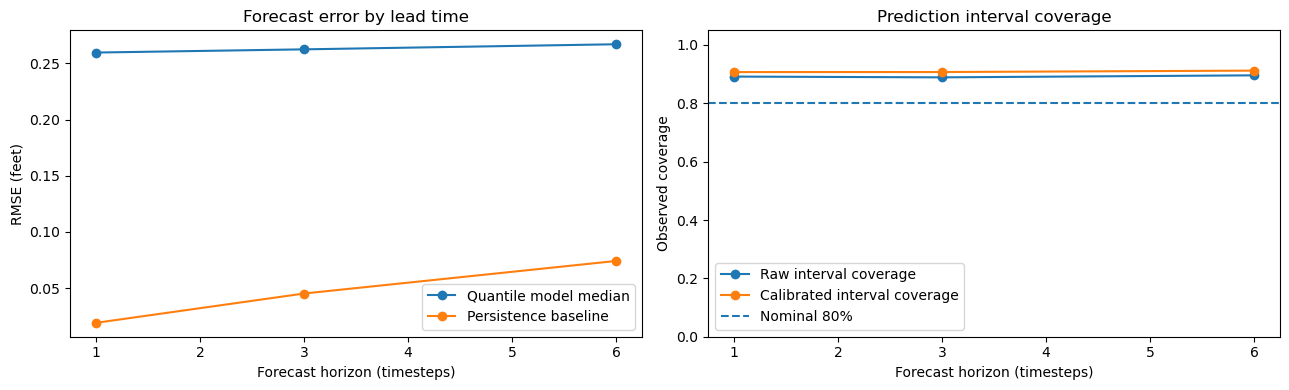

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    evaluation_metrics_df["horizon_steps"],
    evaluation_metrics_df["model_RMSE_ft"],
    marker="o",
    label="Quantile model median",
)
axes[0].plot(
    evaluation_metrics_df["horizon_steps"],
    evaluation_metrics_df["persistence_RMSE_ft"],
    marker="o",
    label="Persistence baseline",
)
axes[0].set_xlabel("Forecast horizon (timesteps)")
axes[0].set_ylabel("RMSE (feet)")
axes[0].set_title("Forecast error by lead time")
axes[0].legend()

axes[1].plot(
    evaluation_metrics_df["horizon_steps"],
    evaluation_metrics_df["raw_80pct_coverage"],
    marker="o",
    label="Raw interval coverage",
)
axes[1].plot(
    evaluation_metrics_df["horizon_steps"],
    evaluation_metrics_df["calibrated_80pct_coverage"],
    marker="o",
    label="Calibrated interval coverage",
)
axes[1].axhline(0.80, linestyle="--", label="Nominal 80%")
axes[1].set_xlabel("Forecast horizon (timesteps)")
axes[1].set_ylabel("Observed coverage")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Prediction interval coverage")
axes[1].legend()

plt.tight_layout()
plt.show()

# Inspect predicted and observed water levels
## This scatter plot gives a visual check of median prediction performance on the final held-out events.

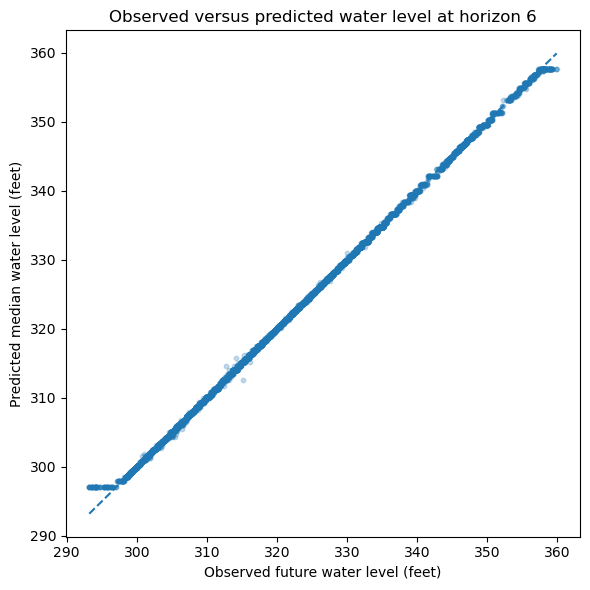

In [19]:
chosen_horizon = HORIZONS[-1]
plot_data = evaluation_predictions[chosen_horizon]
plot_data = plot_data.sample(n=min(12000, len(plot_data)), random_state=RANDOM_STATE)

plt.figure(figsize=(6, 6))
plt.scatter(
    plot_data["actual_water_level_ft"],
    plot_data["predicted_median_ft"],
    alpha=0.25,
    s=10,
)
minimum_value = min(
    plot_data["actual_water_level_ft"].min(),
    plot_data["predicted_median_ft"].min(),
)
maximum_value = max(
    plot_data["actual_water_level_ft"].max(),
    plot_data["predicted_median_ft"].max(),
)
plt.plot([minimum_value, maximum_value], [minimum_value, maximum_value], linestyle="--")
plt.xlabel("Observed future water level (feet)")
plt.ylabel("Predicted median water level (feet)")
plt.title(f"Observed versus predicted water level at horizon {chosen_horizon}")
plt.tight_layout()
plt.show()

# Creating an exploratory surface-hotspot map

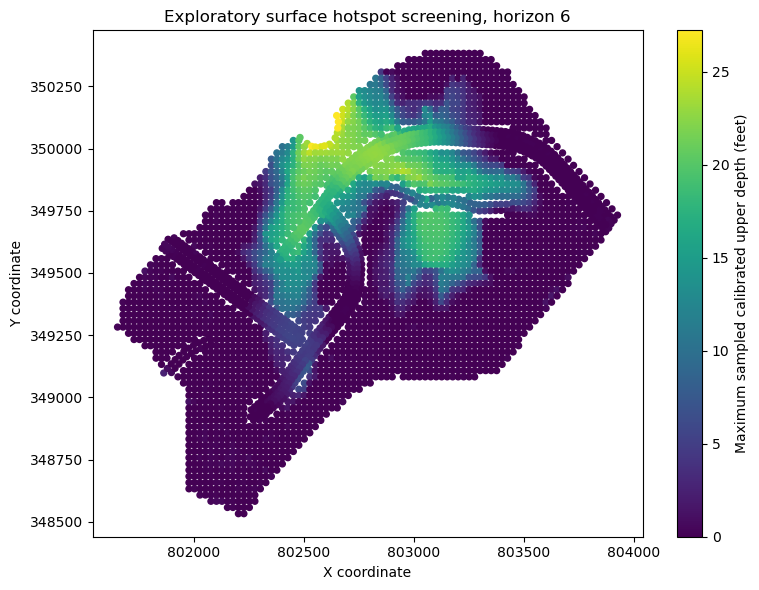

In [20]:
coordinate_x = next((c for c in FEATURE_COLUMNS if "positionx" in normalize_column_name(c)), None)
coordinate_y = next((c for c in FEATURE_COLUMNS if "positiony" in normalize_column_name(c)), None)

if coordinate_x is not None and coordinate_y is not None:
    map_data = evaluation_predictions[chosen_horizon].copy()
    hotspot_data = map_data.groupby("node_id", as_index=False).agg(
        maximum_sampled_upper_depth_ft=("upper_calibrated_depth_ft", "max"),
        maximum_sampled_observed_depth_ft=("actual_depth_ft", "max"),
        x_coordinate=(coordinate_x, "first"),
        y_coordinate=(coordinate_y, "first"),
    )

    plt.figure(figsize=(8, 6))
    points = plt.scatter(
        hotspot_data["x_coordinate"],
        hotspot_data["y_coordinate"],
        c=hotspot_data["maximum_sampled_upper_depth_ft"],
        s=18,
    )
    plt.colorbar(points, label="Maximum sampled calibrated upper depth (feet)")
    plt.xlabel("X coordinate")
    plt.ylabel("Y coordinate")
    plt.title(f"Exploratory surface hotspot screening, horizon {chosen_horizon}")
    plt.tight_layout()
    plt.show()
else:
    print("Coordinate features were not identified. A spatial scatter map was skipped.")